# Pixego: Steganografi LSB Acak Berbasis Kunci dengan Enkripsi AES-256-GCM
### Analisis Kualitas Citra (MSE, PSNR) dan Ketahanan terhadap Chi-Square Attack

Notebook ini adalah implementasi lengkap **Pixego**, aplikasi steganografi untuk tugas kriptografi. Nama Pixego berasal dari kata *pixel* dan *stego*. Isinya dibagi menjadi beberapa bagian supaya mudah dijelaskan saat presentasi.

| Bagian | Isi |
|---|---|
| 1 | Instalasi dan import library |
| 2 | Parameter global |
| 3 | Modul kriptografi (Argon2id, HKDF, AES-256-GCM) |
| 4 | Modul steganografi LSB (sekuensial dan acak berbasis kunci) |
| 5 | Modul metrik kualitas dan steganalisis chi-square |
| 6 | Penyiapan gambar cover |
| 7 | Demo end-to-end |
| 8 | Pengujian fungsional (unit test) |
| 9 | Eksperimen 1: PSNR terhadap bit per kanal dan ukuran pesan |
| 10 | Eksperimen 2: Ketahanan terhadap chi-square attack |
| 11 | Eksperimen 3: Waktu proses |
| 12 | Penyimpanan hasil, catatan keamanan, dan referensi |

**Alur singkat sistem**

```
EMBED   : password --Argon2id--> master key --HKDF--> kunci AES + kunci posisi
          pesan --AES-256-GCM--> ciphertext --LSB (posisi acak)--> stego image (PNG)

EXTRACT : stego image --> baca header --> turunkan kunci lagi --> baca bit di posisi yang sama
          --> AES-256-GCM decrypt (tag salah = password salah atau gambar diubah)
```

## 1. Instalasi dan Import Library

Sel di bawah memasang library yang dibutuhkan. Kalau dijalankan di Google Colab, library ini biasanya sudah ada kecuali `argon2-cffi`, jadi sel ini tetap perlu dijalankan sekali.

In [1]:
%pip install -q cryptography argon2-cffi pillow numpy scipy matplotlib pandas

In [2]:
import os
import io
import math
import time
import struct

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
from scipy.stats import chi2 as chi2_dist

from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes
from cryptography.exceptions import InvalidTag
from argon2.low_level import hash_secret_raw, Type

plt.rcParams["figure.dpi"] = 110
print("Semua library berhasil di-import.")

Semua library berhasil di-import.


## 2. Parameter Global

Semua konstanta dikumpulkan di satu tempat supaya mudah dijelaskan dan diubah.

**Tentang parameter Argon2id.** Nilai di bawah (memori 64 MiB, 3 iterasi, 4 paralelisme) mengikuti salah satu opsi yang dibahas pada RFC 9106 untuk lingkungan dengan memori terbatas. Sebelum menulis laporan, **buka RFC 9106 bagian rekomendasi parameter dan OWASP Password Storage Cheat Sheet**, lalu cocokkan dengan angka yang kamu pakai. Rekomendasi bisa diperbarui, jadi jangan mengandalkan angka dari catatan ini saja.

**Tentang header.** Header berukuran tetap 26 byte dan ditanam dengan LSB sekuensial 1 bit per kanal di awal gambar. Isinya:

| Field | Ukuran | Fungsi |
|---|---|---|
| Magic `STG1` | 4 byte | Penanda bahwa gambar membawa pesan format ini |
| Mode | 1 byte | 0 = sekuensial, 1 = acak berbasis kunci |
| Bit per kanal | 1 byte | Nilai 1, 2, atau 3 |
| Salt | 16 byte | Untuk Argon2id (salt tidak rahasia) |
| Panjang body | 4 byte | Panjang nonce + ciphertext + tag |

Header ini juga dipakai sebagai *associated data* pada AES-GCM, sehingga kalau ada yang mengubah header, dekripsi gagal.

In [3]:
# Parameter Argon2id (cek ulang ke RFC 9106 dan OWASP sebelum dipakai di laporan)
ARGON2_TIME_COST = 3
ARGON2_MEMORY_KIB = 64 * 1024     # 64 MiB
ARGON2_PARALLELISM = 4
KEY_LEN = 32                      # 256 bit

# Parameter AES-GCM
NONCE_LEN = 12
TAG_LEN = 16

# Format header stego
MAGIC = b"STG1"
SALT_LEN = 16
HEADER_FMT = ">4sBB16sI"          # magic, mode, bits, salt, panjang body
HEADER_LEN = struct.calcsize(HEADER_FMT)   # 26 byte
HEADER_BITS = HEADER_LEN * 8               # 208 bit

MODE_SEQUENTIAL = 0
MODE_RANDOM = 1
MODE_NAMES = {"sequential": MODE_SEQUENTIAL, "random": MODE_RANDOM}

# Batas jumlah kanal untuk mode acak (sekitar 8 megapiksel) agar memori tidak habis
MAX_RANDOM_CHANNELS = 24_000_000

print("Panjang header :", HEADER_LEN, "byte =", HEADER_BITS, "bit")

Panjang header : 26 byte = 208 bit


## 3. Modul Kriptografi

Alurnya:

1. **Argon2id** mengubah password menjadi *master key* 32 byte memakai salt acak 16 byte. Sifatnya lambat dan boros memori sehingga menyulitkan brute force.
2. **HKDF-SHA256** memecah master key menjadi dua kunci yang berbeda tujuan: satu untuk AES-GCM dan satu untuk menentukan posisi penyisipan. Memisahkan kunci untuk tujuan berbeda adalah praktik yang baik.
3. **AES-256-GCM** mengenkripsi pesan sekaligus memberi tag autentikasi. Nonce 12 byte dibuat acak untuk setiap enkripsi.

Kode tidak membuat algoritma sendiri. Semua primitif memakai library `cryptography` dan `argon2-cffi`.

In [4]:
class StegoError(Exception):
    """Error khusus aplikasi: password salah, gambar rusak, kapasitas kurang, dan sebagainya."""


def derive_master_key(password: str, salt: bytes) -> bytes:
    """Password -> master key 32 byte memakai Argon2id."""
    return hash_secret_raw(
        secret=password.encode("utf-8"),
        salt=salt,
        time_cost=ARGON2_TIME_COST,
        memory_cost=ARGON2_MEMORY_KIB,
        parallelism=ARGON2_PARALLELISM,
        hash_len=KEY_LEN,
        type=Type.ID,
    )


def derive_subkeys(master_key: bytes):
    """Master key -> (kunci AES, kunci posisi) memakai HKDF-SHA256 dengan label berbeda."""
    enc_key = HKDF(algorithm=hashes.SHA256(), length=32, salt=None,
                   info=b"stego-enc-v1").derive(master_key)
    pos_key = HKDF(algorithm=hashes.SHA256(), length=32, salt=None,
                   info=b"stego-pos-v1").derive(master_key)
    return enc_key, pos_key


def aes_gcm_encrypt(plaintext: bytes, enc_key: bytes, aad: bytes) -> bytes:
    """Mengembalikan nonce (12B) + ciphertext + tag (16B)."""
    nonce = os.urandom(NONCE_LEN)
    ciphertext_with_tag = AESGCM(enc_key).encrypt(nonce, plaintext, aad)
    return nonce + ciphertext_with_tag


def aes_gcm_decrypt(body: bytes, enc_key: bytes, aad: bytes) -> bytes:
    nonce, ciphertext_with_tag = body[:NONCE_LEN], body[NONCE_LEN:]
    try:
        return AESGCM(enc_key).decrypt(nonce, ciphertext_with_tag, aad)
    except InvalidTag:
        raise StegoError("Dekripsi gagal: password salah atau gambar sudah diubah.") from None

In [5]:
# Uji cepat modul kriptografi
salt = os.urandom(SALT_LEN)
t0 = time.perf_counter()
master = derive_master_key("password-uji", salt)
t_kdf = time.perf_counter() - t0

enc_key, pos_key = derive_subkeys(master)
aad = b"header-contoh"
body = aes_gcm_encrypt(b"halo kriptografi", enc_key, aad)

print(f"Waktu Argon2id        : {t_kdf*1000:.0f} ms")
print("Kunci AES berbeda dari kunci posisi:", enc_key != pos_key)
print("Dekripsi benar        :", aes_gcm_decrypt(body, enc_key, aad))

try:
    aes_gcm_decrypt(body, enc_key, b"aad-salah")
except StegoError as e:
    print("AAD diubah            :", e)

Waktu Argon2id        : 177 ms
Kunci AES berbeda dari kunci posisi: True
Dekripsi benar        : b'halo kriptografi'
AAD diubah            : Dekripsi gagal: password salah atau gambar sudah diubah.


## 4. Modul Steganografi LSB

### Konsep penting

**LSB (Least Significant Bit).** Setiap piksel RGB punya 3 kanal, masing-masing 8 bit. Bit paling akhir dari kanal diganti dengan bit pesan. Dengan `k` bit per kanal, `k` bit terakhir yang diganti.

**Kapasitas.** Jumlah kanal adalah `lebar x tinggi x 3`. Setelah dikurangi 208 kanal untuk header, kapasitas dalam byte adalah `(jumlah kanal - 208) x k / 8`, lalu dikurangi lagi 28 byte untuk nonce dan tag.

**Mode sekuensial.** Bit pesan ditanam berurutan mulai dari kanal ke-209. Perubahan menumpuk di bagian awal gambar sehingga mudah ditangkap uji statistik yang menganalisis gambar secara progresif.

**Mode acak berbasis kunci.** Urutan kanal diacak memakai keystream AES-CTR dari kunci posisi. Bit pesan tersebar di seluruh gambar dan urutannya hanya bisa direproduksi oleh pemilik password. Cara mengacaknya: buat satu angka acak 64 bit untuk setiap slot kanal, lalu urutkan (`argsort`). Karena keystream bersifat deterministik dari kunci, hasilnya sama persis saat ekstraksi dan tidak bergantung pada versi NumPy.

**Catatan memori.** Mode acak membuat satu angka 8 byte untuk tiap kanal. Supaya memori tidak habis, mode acak menolak gambar di atas `MAX_RANDOM_CHANNELS` (24 juta kanal, sekitar 8 megapiksel) dan meminta gambar diperkecil. Mode sekuensial tidak punya batas ini.

In [6]:
# ---------- Fungsi bantu bit ----------
def bytes_to_bits(data: bytes) -> np.ndarray:
    """bytes -> array bit (0/1), urutan MSB dulu."""
    return np.unpackbits(np.frombuffer(data, dtype=np.uint8))


def bits_to_bytes(bits: np.ndarray) -> bytes:
    return np.packbits(bits.astype(np.uint8)).tobytes()


def write_bits(flat: np.ndarray, positions: np.ndarray, bits: np.ndarray, k: int) -> None:
    """Tulis `bits` ke k bit terakhir kanal pada `positions` (in-place)."""
    pad = (-len(bits)) % k
    if pad:
        bits = np.concatenate([bits, np.zeros(pad, dtype=np.uint8)])
    groups = bits.reshape(-1, k)
    weights = (1 << np.arange(k - 1, -1, -1)).astype(np.uint8)
    values = (groups * weights).sum(axis=1).astype(np.uint8)
    pos = positions[:len(values)]
    clear_mask = np.uint8((0xFF << k) & 0xFF)
    flat[pos] = (flat[pos] & clear_mask) | values


def read_bits(flat: np.ndarray, positions: np.ndarray, k: int, n_bits: int) -> np.ndarray:
    """Baca n_bits dari k bit terakhir kanal pada `positions`."""
    n_channels = math.ceil(n_bits / k)
    values = flat[positions[:n_channels]] & np.uint8((1 << k) - 1)
    shifts = np.arange(k - 1, -1, -1).astype(np.uint8)
    bits = ((values[:, None] >> shifts) & 1).reshape(-1)
    return bits[:n_bits]


# ---------- Penentuan posisi ----------
def random_positions(pos_key: bytes, n_slots: int, n_needed: int) -> np.ndarray:
    """
    Urutan acak slot 0..n_slots-1 yang deterministik dari pos_key.
    Keystream AES-CTR -> satu angka uint64 per slot -> argsort stabil.
    """
    encryptor = Cipher(algorithms.AES(pos_key), modes.CTR(b"\x00" * 16)).encryptor()
    stream = encryptor.update(b"\x00" * (8 * n_slots)) + encryptor.finalize()
    randoms = np.frombuffer(stream, dtype="<u8")
    order = np.argsort(randoms, kind="stable")
    return order[:n_needed]


def body_positions(mode_id: int, pos_key: bytes, total_channels: int, n_needed: int) -> np.ndarray:
    n_slots = total_channels - HEADER_BITS
    if mode_id == MODE_SEQUENTIAL:
        return HEADER_BITS + np.arange(n_needed)
    return HEADER_BITS + random_positions(pos_key, n_slots, n_needed)


def capacity_bytes(size, bits: int = 1) -> int:
    """Kapasitas pesan (plaintext) dalam byte untuk gambar berukuran (lebar, tinggi)."""
    total_channels = size[0] * size[1] * 3
    raw = ((total_channels - HEADER_BITS) * bits) // 8
    return max(0, raw - NONCE_LEN - TAG_LEN)

In [7]:
def embed(cover: Image.Image, message, password: str, mode: str = "random", bits: int = 1):
    """
    Enkripsi `message` lalu sisipkan ke `cover`.
    Mengembalikan (stego_image, info).
    """
    if mode not in MODE_NAMES:
        raise StegoError("Mode harus 'sequential' atau 'random'.")
    if bits not in (1, 2, 3):
        raise StegoError("Bit per kanal harus 1, 2, atau 3.")
    if not password:
        raise StegoError("Password tidak boleh kosong.")

    plaintext = message.encode("utf-8") if isinstance(message, str) else bytes(message)

    arr = np.array(cover.convert("RGB"), dtype=np.uint8)
    shape = arr.shape
    flat = arr.reshape(-1).copy()
    total = flat.size
    if mode == "random" and total > MAX_RANDOM_CHANNELS:
        raise StegoError("Gambar terlalu besar untuk mode acak (batas sekitar 8 megapiksel). "
                         "Perkecil gambar dulu, atau pakai mode sequential.")

    body_len = NONCE_LEN + len(plaintext) + TAG_LEN
    channels_needed = math.ceil(body_len * 8 / bits)
    channels_free = total - HEADER_BITS
    if channels_needed > channels_free:
        cap = capacity_bytes(cover.size, bits)
        raise StegoError(f"Pesan terlalu panjang. Kapasitas maksimum {cap} byte "
                         f"untuk gambar ini dengan {bits} bit per kanal.")

    mode_id = MODE_NAMES[mode]
    salt = os.urandom(SALT_LEN)
    header = struct.pack(HEADER_FMT, MAGIC, mode_id, bits, salt, body_len)

    master = derive_master_key(password, salt)
    enc_key, pos_key = derive_subkeys(master)
    body = aes_gcm_encrypt(plaintext, enc_key, aad=header)

    # 1) header: sekuensial, 1 bit per kanal, di awal gambar
    write_bits(flat, np.arange(HEADER_BITS), bytes_to_bits(header), 1)
    # 2) body: posisi sesuai mode, k bit per kanal
    pos = body_positions(mode_id, pos_key, total, channels_needed)
    write_bits(flat, pos, bytes_to_bits(body), bits)

    stego = Image.fromarray(flat.reshape(shape))
    info = {
        "mode": mode,
        "bits_per_channel": bits,
        "ukuran_gambar": cover.size,
        "pesan_byte": len(plaintext),
        "body_byte": body_len,
        "kanal_dipakai": channels_needed,
        "kapasitas_byte": capacity_bytes(cover.size, bits),
        "penggunaan_kapasitas_%": round(100 * len(plaintext) / max(1, capacity_bytes(cover.size, bits)), 2),
    }
    return stego, info


def extract(stego: Image.Image, password: str) -> bytes:
    """Ekstrak dan dekripsi pesan. Melempar StegoError kalau gagal."""
    flat = np.array(stego.convert("RGB"), dtype=np.uint8).reshape(-1)
    total = flat.size
    if total <= HEADER_BITS:
        raise StegoError("Gambar terlalu kecil.")

    header = bits_to_bytes(flat[:HEADER_BITS] & 1)
    magic, mode_id, bits, salt, body_len = struct.unpack(HEADER_FMT, header)

    if magic != MAGIC:
        raise StegoError("Tidak ditemukan pesan tersembunyi (header tidak valid). "
                         "Mungkin gambar sudah dikompres atau diubah.")
    if mode_id not in (MODE_SEQUENTIAL, MODE_RANDOM) or bits not in (1, 2, 3):
        raise StegoError("Header rusak.")
    channels_needed = math.ceil(body_len * 8 / bits)
    if body_len < NONCE_LEN + TAG_LEN or channels_needed > total - HEADER_BITS:
        raise StegoError("Panjang data pada header tidak masuk akal.")
    if mode_id == MODE_RANDOM and total > MAX_RANDOM_CHANNELS:
        raise StegoError("Gambar terlalu besar untuk diproses pada mode acak. Perkecil gambar.")

    master = derive_master_key(password, salt)
    enc_key, pos_key = derive_subkeys(master)
    pos = body_positions(mode_id, pos_key, total, channels_needed)
    body = bits_to_bytes(read_bits(flat, pos, bits, body_len * 8))
    return aes_gcm_decrypt(body, enc_key, aad=header)

## 5. Metrik Kualitas dan Steganalisis Chi-Square

### MSE dan PSNR

```
MSE  = rata-rata ( (piksel_asli - piksel_stego)^2 )
PSNR = 10 * log10( 255^2 / MSE )      satuan dB
```

PSNR makin tinggi berarti stego image makin mirip gambar asli. Kalau MSE sama dengan nol (gambar identik), PSNR tak hingga.

### Chi-square attack (Westfeld dan Pfitzmann)

Ide dasarnya: kalau bit LSB diganti dengan bit acak (hasil enkripsi), maka dua nilai yang berpasangan, yaitu `2i` dan `2i+1`, cenderung menjadi sama sering muncul. Uji chi-square membandingkan frekuensi nilai genap `h[2i]` dengan frekuensi yang diharapkan jika pasangan sudah seimbang, yaitu `(h[2i] + h[2i+1]) / 2`.

```
chi2 = jumlah dari ( h[2i] - e[i] )^2 / e[i]       dengan e[i] = (h[2i] + h[2i+1]) / 2
p    = 1 - CDF_chi2( chi2, derajat_bebas = jumlah_pasangan - 1 )
```

Cara membaca `p`: nilai mendekati **1** berarti pasangan nilai sangat seimbang sehingga **dicurigai ada data tersembunyi**. Nilai mendekati **0** berarti distribusi tidak seimbang sehingga gambar dianggap bersih.

Pasangan dengan frekuensi harapan kurang dari 5 dibuang agar pendekatan chi-square tetap wajar. Ini penyederhanaan yang umum dan perlu kamu tulis di laporan.

Versi **progresif**: uji dihitung pada x% piksel pertama (urut dari kiri atas), lalu x dinaikkan bertahap. Pada penyisipan sekuensial, p-value jatuh di titik tempat pesan berakhir sehingga ketahuan.

In [8]:
def to_array(img: Image.Image) -> np.ndarray:
    return np.array(img.convert("RGB"), dtype=np.uint8)


def mse(a: Image.Image, b: Image.Image) -> float:
    x = to_array(a).astype(np.float64)
    y = to_array(b).astype(np.float64)
    return float(np.mean((x - y) ** 2))


def psnr(a: Image.Image, b: Image.Image) -> float:
    m = mse(a, b)
    return float("inf") if m == 0 else 10 * math.log10(255.0 ** 2 / m)


def difference_image(a: Image.Image, b: Image.Image, gain: int = 255) -> Image.Image:
    """Selisih mutlak yang diperkuat supaya piksel berubah terlihat."""
    d = np.abs(to_array(a).astype(np.int16) - to_array(b).astype(np.int16))
    return Image.fromarray(np.clip(d * gain, 0, 255).astype(np.uint8))


def lsb_plane(img: Image.Image, channel: int = 0) -> Image.Image:
    """Bidang LSB satu kanal (hitam = 0, putih = 1). Dipakai untuk serangan visual."""
    return Image.fromarray(((to_array(img)[:, :, channel] & 1) * 255).astype(np.uint8))


def chi_square_test(values: np.ndarray, min_expected: float = 5.0):
    """
    Uji chi-square pasangan nilai (2i, 2i+1).
    Mengembalikan (p_value, statistik, jumlah_pasangan_dipakai).
    p mendekati 1 = dicurigai ada data tersembunyi.
    """
    hist = np.bincount(values, minlength=256).astype(np.float64)
    even, odd = hist[0::2], hist[1::2]
    expected = (even + odd) / 2.0
    keep = expected >= min_expected
    n_pairs = int(keep.sum())
    if n_pairs < 2:
        return float("nan"), float("nan"), n_pairs
    stat = float(np.sum((even[keep] - expected[keep]) ** 2 / expected[keep]))
    p = float(chi2_dist.sf(stat, n_pairs - 1))
    return p, stat, n_pairs


def chi_square_full(img: Image.Image) -> float:
    """p-value chi-square untuk seluruh gambar (semua kanal digabung)."""
    return chi_square_test(to_array(img).reshape(-1))[0]


def chi_square_progressive(img: Image.Image, steps: int = 20):
    """p-value pada x% data pertama, x = 5%, 10%, ..., 100%."""
    flat = to_array(img).reshape(-1)
    fractions = np.linspace(1 / steps, 1.0, steps)
    p_values = [chi_square_test(flat[:int(f * len(flat))])[0] for f in fractions]
    return fractions * 100, np.array(p_values)


def load_cover(source, max_side=None) -> Image.Image:
    """
    Membuka gambar COVER dengan aman. `source` boleh path file atau file-like object.
    - Rotasi EXIF diterapkan (foto HP sering tersimpan miring dengan info rotasi di EXIF).
    - Transparansi (alpha) diratakan di atas latar putih.
    - Palet warna (GIF, PNG 8-bit) diubah ke RGB. GIF animasi hanya frame pertama.
    - Kalau max_side diisi dan gambar lebih besar, gambar diperkecil dengan rasio tetap.
    Jangan pakai fungsi ini untuk STEGO image, karena rotasi atau resize merusak pesan.
    """
    try:
        img = Image.open(source)
        img = ImageOps.exif_transpose(img)
        has_alpha = img.mode in ("RGBA", "LA", "PA") or "transparency" in img.info
        if has_alpha:
            rgba = img.convert("RGBA")
            background = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
            img = Image.alpha_composite(background, rgba).convert("RGB")
        else:
            img = img.convert("RGB")
    except StegoError:
        raise
    except Exception as e:
        raise StegoError(f"Gambar tidak bisa dibuka ({type(e).__name__}). "
                         "Format HEIC/HEIF perlu dikonversi ke PNG atau JPG dulu.") from None
    if max_side and max(img.size) > max_side:
        img.thumbnail((max_side, max_side), Image.LANCZOS)
    return img

## 6. Penyiapan Gambar Cover

Agar notebook bisa langsung jalan tanpa file tambahan, kode membuat **dua gambar sintetis** dengan karakter berbeda:

- `tekstur`: gradasi warna halus ditambah noise, mirip foto yang ramai.
- `polos`: banyak area warna rata dan bentuk geometris, mirip grafis atau tangkapan layar.

Perbedaan karakter ini penting karena uji chi-square bekerja sangat berbeda pada keduanya.

**Untuk laporan, gunakan juga gambar asli.** Isi `USER_COVER_PATHS` dengan file PNG atau JPG milikmu sendiri atau dari dataset gambar terbuka yang boleh dipakai. Gambar sintetis hanya untuk verifikasi bahwa kode benar. Kalau kamu memakai gambar dari sumber lain, catat sumber dan lisensinya di laporan.

Gambar milikmu dibuka lewat fungsi `load_cover`, yang menangani hal-hal berikut:

| Kasus | Perlakuan |
|---|---|
| Foto HP dengan info rotasi EXIF | Rotasi diterapkan agar gambar tidak miring |
| PNG transparan (alpha) | Diratakan di atas latar putih |
| GIF atau PNG palet | Diubah ke RGB, GIF animasi hanya frame pertama |
| Gambar sangat besar | Diperkecil ke `MAX_SIDE` dengan rasio tetap |
| File rusak atau HEIC | Muncul pesan error yang jelas, bukan crash |

Semua perlakuan ini hanya untuk **cover**. Stego image tidak boleh dirotasi atau diperkecil karena pesan akan hilang.

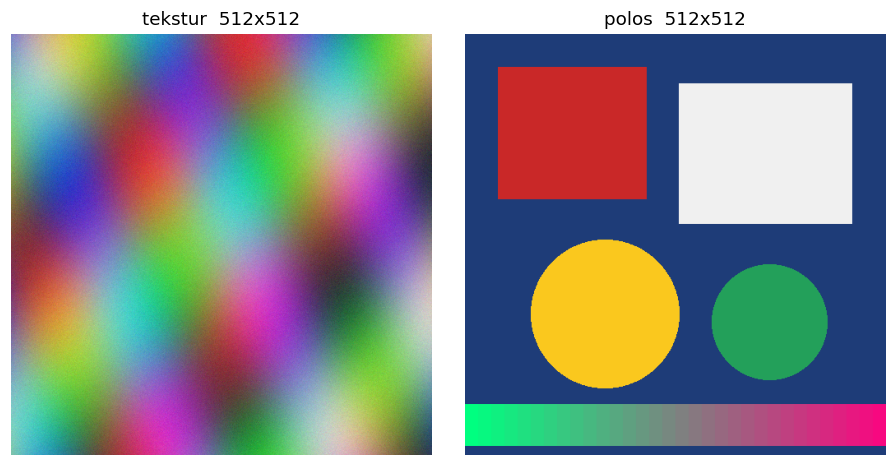

Kapasitas (byte) per gambar dan bit per kanal:
       tekstur   polos
1 bit    98250   98250
2 bit   196528  196528
3 bit   294806  294806


In [9]:
# Isi dengan path gambarmu sendiri, contoh: {"foto_kampus": "foto_kampus.png"}
USER_COVER_PATHS = {}
MAX_SIDE = 768          # gambar dikecilkan agar proses cepat dan hemat memori


def make_textured_cover(width=512, height=512, seed=7) -> Image.Image:
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[0:height, 0:width]
    r = 128 + 90 * np.sin(x / 37.0) * np.cos(y / 53.0)
    g = 128 + 80 * np.sin((x + y) / 61.0)
    b = 128 + 70 * np.cos(x / 29.0 - y / 71.0)
    img = np.stack([r, g, b], axis=-1) + rng.normal(0, 6, (height, width, 3))
    return Image.fromarray(np.clip(img, 0, 255).astype(np.uint8))


def make_flat_cover(width=512, height=512) -> Image.Image:
    img = Image.new("RGB", (width, height), (30, 60, 120))
    d = ImageDraw.Draw(img)
    d.rectangle([40, 40, 220, 200], fill=(201, 40, 40))
    d.rectangle([260, 60, 470, 230], fill=(240, 240, 240))
    d.ellipse([80, 250, 260, 430], fill=(250, 200, 30))
    d.ellipse([300, 280, 440, 420], fill=(35, 160, 90))
    for i in range(0, width, 16):          # pita gradasi bertingkat
        v = int(255 * i / width)
        d.rectangle([i, 450, i + 16, 500], fill=(v, 255 - v, 128))
    return img


covers = {"tekstur": make_textured_cover(), "polos": make_flat_cover()}
for name, path in USER_COVER_PATHS.items():
    covers[name] = load_cover(path, max_side=MAX_SIDE)

fig, axes = plt.subplots(1, len(covers), figsize=(4.2 * len(covers), 4.2))
axes = np.atleast_1d(axes)
for ax, (name, im) in zip(axes, covers.items()):
    ax.imshow(im)
    ax.set_title(f"{name}  {im.size[0]}x{im.size[1]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Kapasitas (byte) per gambar dan bit per kanal:")
print(pd.DataFrame({n: {f"{k} bit": capacity_bytes(im.size, k) for k in (1, 2, 3)}
                    for n, im in covers.items()}))

**Opsional untuk Google Colab:** sel di bawah memungkinkan unggah gambar sendiri. Lewati kalau kamu menjalankan di Jupyter lokal dan cukup mengisi `USER_COVER_PATHS` di atas.

In [10]:
# Opsional (Colab saja): unggah gambar sendiri, lalu jalankan ulang sel penyiapan cover di atas
try:
    from google.colab import files
    uploaded = files.upload()
    for fname in uploaded:
        USER_COVER_PATHS[os.path.splitext(fname)[0]] = fname
    print("Gambar terunggah:", list(USER_COVER_PATHS))
    print("Jalankan ulang sel penyiapan cover di atas supaya gambar ini ikut dimuat.")
except ImportError:
    print("Bukan Colab. Isi USER_COVER_PATHS secara manual kalau ingin memakai gambar sendiri.")

Bukan Colab. Isi USER_COVER_PATHS secara manual kalau ingin memakai gambar sendiri.


## 7. Demo End-to-End

Ubah `pesan`, `password`, `mode`, dan `bits` sesuai keinginan. Demo ini memperlihatkan:

1. Gambar asli dan stego tampak identik.
2. Nilai MSE dan PSNR.
3. Gambar selisih yang diperkuat dan bidang LSB.
4. Ekstraksi dengan password benar dan salah.

In [11]:
pesan = "Rapat panitia dipindah ke hari Jumat pukul 19.00 di ruang B2. Jangan disebarkan dulu."
password = "contoh-password-yang-cukup-panjang-2026"
mode = "random"       # "random" atau "sequential"
bits = 1              # 1, 2, atau 3
cover = covers["tekstur"]

stego, info = embed(cover, pesan, password, mode=mode, bits=bits)
print("Info embedding:")
for k, v in info.items():
    print(f"  {k:26s}: {v}")

print(f"\nMSE  : {mse(cover, stego):.6f}")
print(f"PSNR : {psnr(cover, stego):.2f} dB")

stego.save("stego_demo.png")          # WAJIB format lossless (PNG)
hasil = extract(Image.open("stego_demo.png"), password).decode("utf-8")
print("\nPesan hasil ekstraksi:", hasil)
assert hasil == pesan

Info embedding:
  mode                      : random
  bits_per_channel          : 1
  ukuran_gambar             : (512, 512)
  pesan_byte                : 85
  body_byte                 : 113
  kanal_dipakai             : 904
  kapasitas_byte            : 98250
  penggunaan_kapasitas_%    : 0.09

MSE  : 0.000702
PSNR : 79.67 dB



Pesan hasil ekstraksi: Rapat panitia dipindah ke hari Jumat pukul 19.00 di ruang B2. Jangan disebarkan dulu.


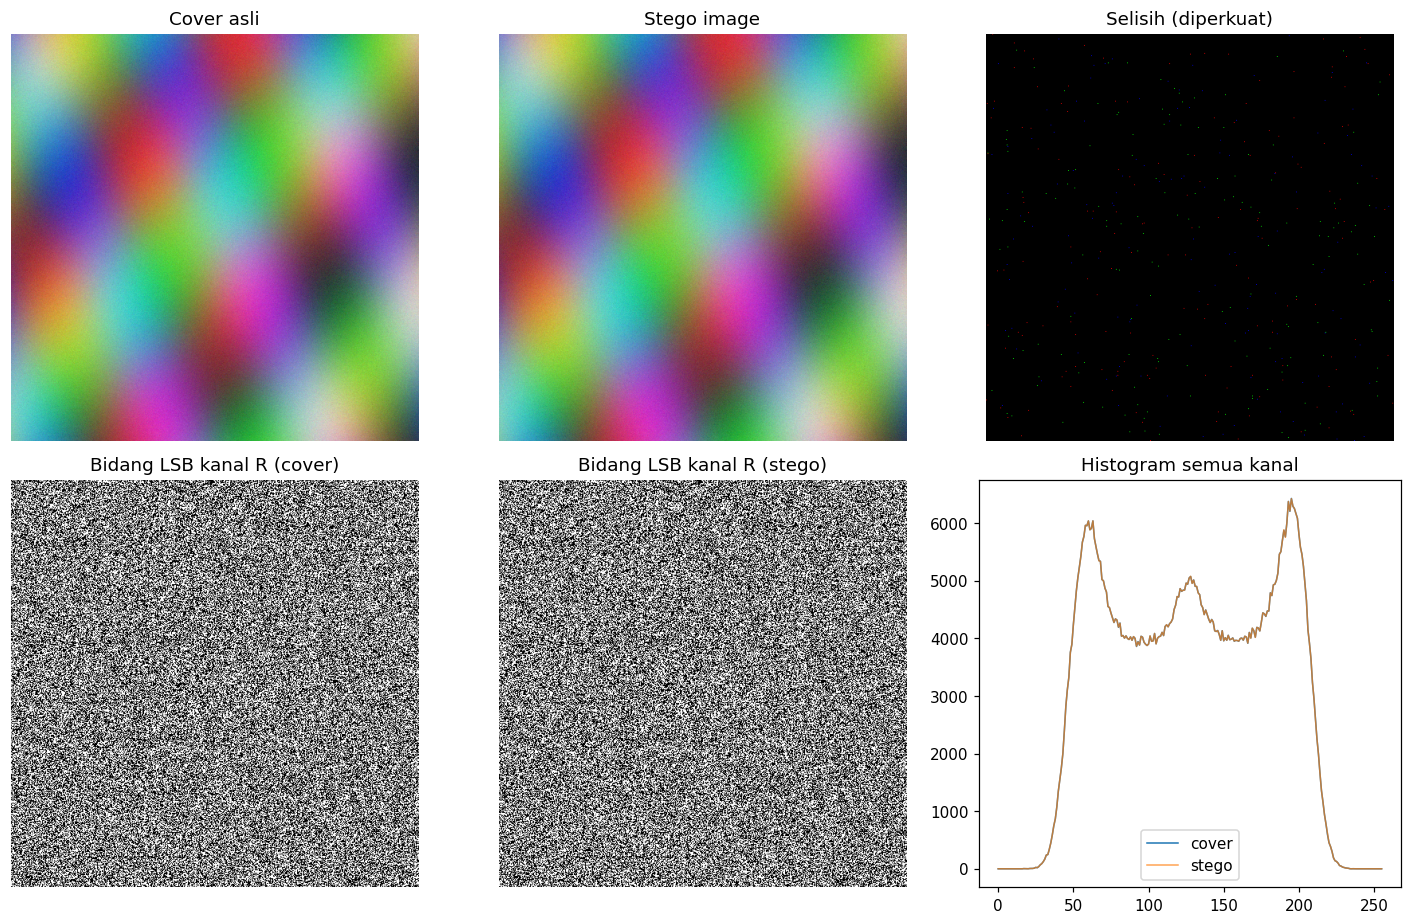

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
axes[0, 0].imshow(cover)
axes[0, 0].set_title("Cover asli")
axes[0, 1].imshow(stego)
axes[0, 1].set_title("Stego image")
axes[0, 2].imshow(difference_image(cover, stego))
axes[0, 2].set_title("Selisih (diperkuat)")
axes[1, 0].imshow(lsb_plane(cover), cmap="gray")
axes[1, 0].set_title("Bidang LSB kanal R (cover)")
axes[1, 1].imshow(lsb_plane(stego), cmap="gray")
axes[1, 1].set_title("Bidang LSB kanal R (stego)")

h_c = np.bincount(to_array(cover).reshape(-1), minlength=256)
h_s = np.bincount(to_array(stego).reshape(-1), minlength=256)
axes[1, 2].plot(h_c, label="cover", linewidth=1)
axes[1, 2].plot(h_s, label="stego", linewidth=1, alpha=0.7)
axes[1, 2].set_title("Histogram semua kanal")
axes[1, 2].legend()

for ax in axes.ravel()[:5]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Ekstraksi dengan password salah
try:
    extract(Image.open("stego_demo.png"), "password-yang-salah")
except StegoError as e:
    print("Password salah  ->", e)

# Ekstraksi dari gambar cover (tanpa pesan)
try:
    extract(cover, password)
except StegoError as e:
    print("Tanpa pesan     ->", e)

Password salah  -> Dekripsi gagal: password salah atau gambar sudah diubah.
Tanpa pesan     -> Tidak ditemukan pesan tersembunyi (header tidak valid). Mungkin gambar sudah dikompres atau diubah.


## 8. Pengujian Fungsional (Unit Test)

Sel ini menguji banyak skenario sekaligus. Kalau semua `assert` lolos, sistem berfungsi sesuai rancangan. Hasilnya bisa kamu masukkan ke bab pengujian sebagai tabel skenario uji.

| Skenario | Hasil yang diharapkan |
|---|---|
| Embed lalu extract dengan password benar (semua mode dan bit) | Pesan kembali utuh |
| Password salah | `StegoError` |
| Bit di area body dibalik | `StegoError` (tag GCM tidak cocok) |
| Gambar disimpan sebagai JPEG | `StegoError` (LSB rusak oleh kompresi lossy) |
| Pesan melebihi kapasitas | `StegoError` |
| Gambar tanpa pesan | `StegoError` |
| Pesan kosong dan pesan biner | Berhasil |

In [14]:
def expect_error(fn, label):
    try:
        fn()
    except StegoError as e:
        print(f"[LOLOS] {label:45s} -> {e}")
        return
    raise AssertionError(f"{label}: seharusnya gagal tetapi berhasil")


test_cover = covers["tekstur"]
rows = []

# 1. Roundtrip semua kombinasi mode dan bit
for mode_name in ("sequential", "random"):
    for k in (1, 2, 3):
        msg = ("Uji roundtrip %s %d bit. " % (mode_name, k)) * 20
        st, _ = embed(test_cover, msg, "pw-uji-123", mode=mode_name, bits=k)
        out = extract(st, "pw-uji-123").decode("utf-8")
        assert out == msg
        rows.append({"mode": mode_name, "bit": k, "roundtrip": "lolos"})
print(pd.DataFrame(rows).to_string(index=False))
print()

stego_ok, _ = embed(test_cover, "pesan uji", "pw-uji-123", mode="random", bits=1)

# 2. Password salah
expect_error(lambda: extract(stego_ok, "pw-salah"), "Password salah")

# 3. Body dirusak: balik LSB semua kanal setelah header
arr = to_array(stego_ok).reshape(-1).copy()
arr[HEADER_BITS:] ^= 1
tampered = Image.fromarray(arr.reshape(to_array(stego_ok).shape))
expect_error(lambda: extract(tampered, "pw-uji-123"), "Body dirusak (tag GCM)")

# 4. Simpan sebagai JPEG
buf = io.BytesIO()
stego_ok.save(buf, format="JPEG", quality=95)
buf.seek(0)
jpeg_img = Image.open(buf)
expect_error(lambda: extract(jpeg_img, "pw-uji-123"), "Stego disimpan sebagai JPEG q=95")

# 5. Melebihi kapasitas
too_big = os.urandom(capacity_bytes(test_cover.size, 1) + 1)
expect_error(lambda: embed(test_cover, too_big, "pw", bits=1), "Pesan melebihi kapasitas")

# 6. Gambar tanpa pesan
expect_error(lambda: extract(test_cover, "pw-uji-123"), "Gambar tanpa pesan")

# 7. Pesan kosong dan pesan biner
st, _ = embed(test_cover, b"", "pw", mode="random")
assert extract(st, "pw") == b""
blob = os.urandom(500)
st, _ = embed(test_cover, blob, "pw", mode="sequential", bits=2)
assert extract(st, "pw") == blob
print("[LOLOS] Pesan kosong dan pesan biner berhasil")

# 8. Dua kali embed pesan sama menghasilkan stego berbeda (salt dan nonce acak)
a, _ = embed(test_cover, "sama", "pw")
b, _ = embed(test_cover, "sama", "pw")
assert not np.array_equal(to_array(a), to_array(b))
print("[LOLOS] Embed ulang pesan yang sama menghasilkan stego berbeda")

# 9. Pemuatan cover: PNG transparan diratakan di atas putih
transparan = Image.new("RGBA", (30, 30), (0, 0, 0, 0))
buf = io.BytesIO()
transparan.save(buf, format="PNG")
buf.seek(0)
assert (to_array(load_cover(buf)) == 255).all()
print("[LOLOS] PNG transparan diratakan di atas latar putih")

# 10. Pemuatan cover: rotasi EXIF diterapkan (orientasi 6 menukar lebar dan tinggi)
exif = Image.Exif()
exif[0x0112] = 6
buf = io.BytesIO()
Image.new("RGB", (40, 20), (10, 20, 30)).save(buf, format="JPEG", exif=exif)
buf.seek(0)
assert load_cover(buf).size == (20, 40)
print("[LOLOS] Rotasi EXIF diterapkan pada cover")

# 11. Pemuatan cover: pengecilan otomatis dan file yang bukan gambar
buf = io.BytesIO()
Image.new("RGB", (400, 200)).save(buf, format="PNG")
buf.seek(0)
assert max(load_cover(buf, max_side=100).size) == 100
expect_error(lambda: load_cover(io.BytesIO(b"ini bukan gambar")), "File bukan gambar")

# 12. Gambar terlalu kecil untuk header
expect_error(lambda: embed(Image.new("RGB", (8, 8)), "x", "pw"), "Gambar terlalu kecil")

print("\nSemua pengujian fungsional lolos.")

      mode  bit roundtrip
sequential    1     lolos
sequential    2     lolos
sequential    3     lolos
    random    1     lolos
    random    2     lolos
    random    3     lolos



[LOLOS] Password salah                                -> Dekripsi gagal: password salah atau gambar sudah diubah.


[LOLOS] Body dirusak (tag GCM)                        -> Dekripsi gagal: password salah atau gambar sudah diubah.
[LOLOS] Stego disimpan sebagai JPEG q=95              -> Tidak ditemukan pesan tersembunyi (header tidak valid). Mungkin gambar sudah dikompres atau diubah.
[LOLOS] Pesan melebihi kapasitas                      -> Pesan terlalu panjang. Kapasitas maksimum 98250 byte untuk gambar ini dengan 1 bit per kanal.
[LOLOS] Gambar tanpa pesan                            -> Tidak ditemukan pesan tersembunyi (header tidak valid). Mungkin gambar sudah dikompres atau diubah.


[LOLOS] Pesan kosong dan pesan biner berhasil


[LOLOS] Embed ulang pesan yang sama menghasilkan stego berbeda
[LOLOS] PNG transparan diratakan di atas latar putih
[LOLOS] Rotasi EXIF diterapkan pada cover
[LOLOS] File bukan gambar                             -> Gambar tidak bisa dibuka (UnidentifiedImageError). Format HEIC/HEIF perlu dikonversi ke PNG atau JPG dulu.
[LOLOS] Gambar terlalu kecil                          -> Pesan terlalu panjang. Kapasitas maksimum 0 byte untuk gambar ini dengan 1 bit per kanal.

Semua pengujian fungsional lolos.


## 9. Eksperimen 1: PSNR terhadap Bit per Kanal dan Ukuran Pesan

**Pertanyaan penelitian:** bagaimana kualitas gambar berubah ketika bit per kanal dan ukuran pesan bertambah?

Teori singkat: pada 1 bit per kanal, kanal yang dipakai berubah paling banyak sebesar 1. Pada 2 dan 3 bit, perubahan maksimum membesar menjadi 3 dan 7, sehingga PSNR turun. Namun kamu **tidak boleh menulis angka dari teori ini sebagai hasil**. Tulis angka dari tabel yang dihasilkan sel di bawah.

Pesan uji adalah teks acak yang dapat dicetak, dengan seed tetap agar hasil bisa direproduksi.

In [15]:
PASSWORD_EXP = "password-eksperimen-2026"
MESSAGE_SIZES = [100, 1024, 10 * 1024, 50 * 1024]      # byte
rng_msg = np.random.default_rng(2026)


def random_message(n: int) -> bytes:
    return bytes(rng_msg.integers(32, 127, size=n, dtype=np.uint8))


records = []
for cover_name, cv in covers.items():
    for k in (1, 2, 3):
        for size in MESSAGE_SIZES:
            if size > capacity_bytes(cv.size, k):
                continue
            msg = random_message(size)
            for mode_name in ("sequential", "random"):
                st, inf = embed(cv, msg, PASSWORD_EXP, mode=mode_name, bits=k)
                records.append({
                    "cover": cover_name, "bit": k, "pesan_byte": size, "mode": mode_name,
                    "penggunaan_%": inf["penggunaan_kapasitas_%"],
                    "MSE": mse(cv, st), "PSNR_dB": psnr(cv, st),
                })

df_psnr = pd.DataFrame(records)
display_df = df_psnr.copy()
display_df["MSE"] = display_df["MSE"].round(6)
display_df["PSNR_dB"] = display_df["PSNR_dB"].round(2)
display_df

,cover,bit,pesan_byte,mode,penggunaan_%,MSE,PSNR_dB
0,tekstur,1,100,sequential,0.10,0.000771,79.26
1,tekstur,1,100,random,0.10,0.000763,79.31
2,tekstur,1,1024,sequential,1.04,0.005549,70.69
3,tekstur,1,1024,random,1.04,0.005491,70.73
4,tekstur,1,10240,sequential,10.42,0.052326,60.94
5,tekstur,1,10240,random,10.42,0.052258,60.95
6,tekstur,1,51200,sequential,52.11,0.260632,53.97
7,tekstur,1,51200,random,52.11,0.260677,53.97
8,tekstur,2,100,sequential,0.05,0.001756,75.69
9,tekstur,2,100,random,0.05,0.001779,75.63


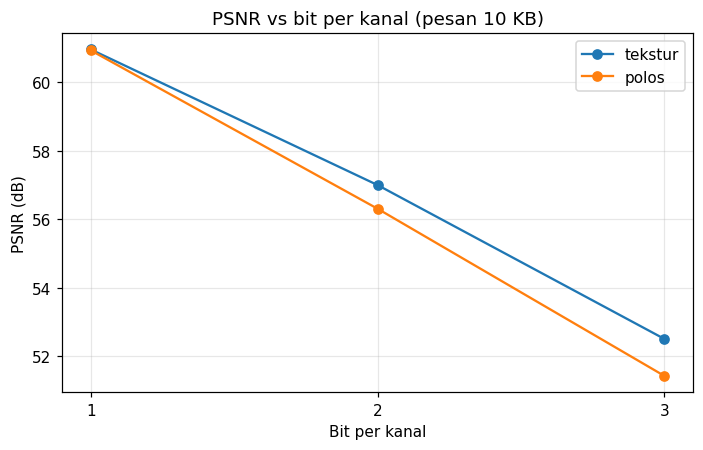

In [16]:
# Grafik PSNR vs bit per kanal untuk ukuran pesan tertentu (mode acak)
target_size = 10 * 1024
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for cover_name in covers:
    sub = df_psnr[(df_psnr.cover == cover_name) & (df_psnr.pesan_byte == target_size) &
                  (df_psnr["mode"] == "random")].sort_values("bit")
    ax.plot(sub["bit"], sub["PSNR_dB"], marker="o", label=cover_name)
ax.set_xlabel("Bit per kanal")
ax.set_ylabel("PSNR (dB)")
ax.set_xticks([1, 2, 3])
ax.set_title(f"PSNR vs bit per kanal (pesan {target_size // 1024} KB)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Eksperimen 2: Ketahanan terhadap Chi-Square Attack

**Pertanyaan penelitian:** apakah penyisipan acak berbasis kunci lebih sulit dideteksi uji chi-square dibanding penyisipan sekuensial?

Dua pengukuran:

1. **Tabel p-value seluruh gambar** pada berbagai tingkat penggunaan kapasitas (10%, 25%, 50%, 100%) dengan 1 bit per kanal.
2. **Kurva progresif** pada penggunaan kapasitas 50%.

Ingat cara membaca p-value: dekat **1** berarti dicurigai stego, dekat **0** berarti dianggap bersih. Perhatikan juga p-value gambar **cover asli** sebagai pembanding dasar. Kalau cover asli sudah punya p-value tinggi, uji ini tidak bisa membedakan stego dari cover pada gambar tersebut, dan itu temuan yang sah untuk dibahas.

In [17]:
RATES = [0.10, 0.25, 0.50, 1.00]
rows = []
for cover_name, cv in covers.items():
    cap = capacity_bytes(cv.size, 1)
    p_cover = chi_square_full(cv)
    rows.append({"cover": cover_name, "mode": "cover asli", "penggunaan_kapasitas": "0%",
                 "p_value": p_cover})
    for rate in RATES:
        msg = random_message(int(cap * rate))
        for mode_name in ("sequential", "random"):
            st, _ = embed(cv, msg, PASSWORD_EXP, mode=mode_name, bits=1)
            rows.append({"cover": cover_name, "mode": mode_name,
                         "penggunaan_kapasitas": f"{int(rate * 100)}%",
                         "p_value": chi_square_full(st)})

df_chi = pd.DataFrame(rows)
df_chi["p_value"] = df_chi["p_value"].round(4)
df_chi

,cover,mode,penggunaan_kapasitas,p_value
0,tekstur,cover asli,0%,0.0000
1,tekstur,sequential,10%,0.0000
2,tekstur,random,10%,0.0000
3,tekstur,sequential,25%,0.0000
4,tekstur,random,25%,0.0001
5,tekstur,sequential,50%,0.2073
6,tekstur,random,50%,0.4782
7,tekstur,sequential,100%,0.9995
8,tekstur,random,100%,1.0000
9,polos,cover asli,0%,0.0000


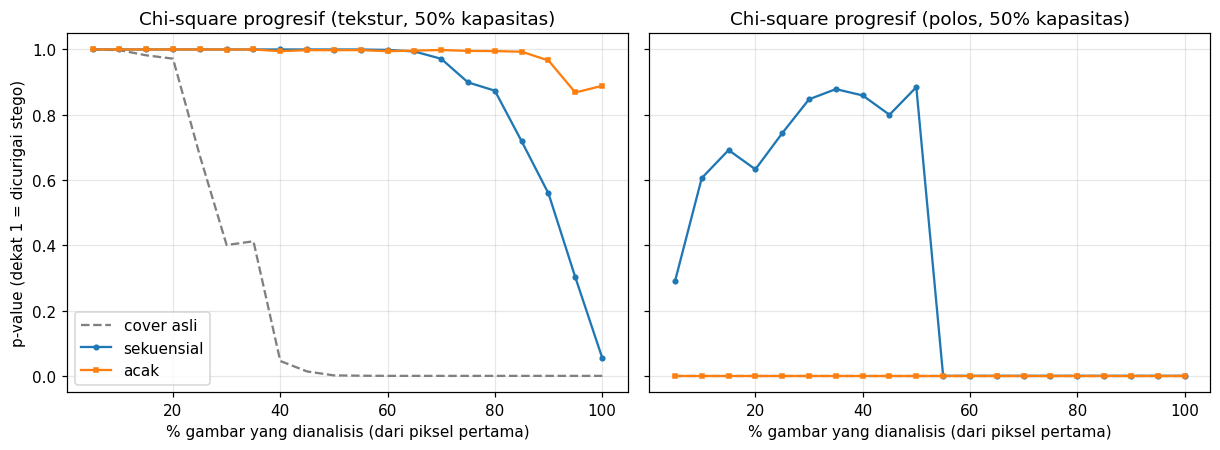

In [18]:
# Kurva progresif pada 50% kapasitas
fig, axes = plt.subplots(1, len(covers), figsize=(5.6 * len(covers), 4.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, (cover_name, cv) in zip(axes, covers.items()):
    cap = capacity_bytes(cv.size, 1)
    msg = random_message(int(cap * 0.5))
    x, p0 = chi_square_progressive(cv)
    st_seq, _ = embed(cv, msg, PASSWORD_EXP, mode="sequential", bits=1)
    st_rnd, _ = embed(cv, msg, PASSWORD_EXP, mode="random", bits=1)
    _, p_seq = chi_square_progressive(st_seq)
    _, p_rnd = chi_square_progressive(st_rnd)
    ax.plot(x, p0, label="cover asli", linestyle="--", color="gray")
    ax.plot(x, p_seq, label="sekuensial", marker="o", markersize=3)
    ax.plot(x, p_rnd, label="acak", marker="s", markersize=3)
    ax.set_title(f"Chi-square progresif ({cover_name}, 50% kapasitas)")
    ax.set_xlabel("% gambar yang dianalisis (dari piksel pertama)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("p-value (dekat 1 = dicurigai stego)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Dua hal penting saat membaca hasil di atas:**

- **Tabel p-value seluruh gambar tidak peka terhadap urutan penyisipan.** Histogram seluruh gambar hanya menghitung berapa kali tiap nilai muncul, bukan di mana letaknya. Karena itu mode sekuensial dan acak akan menghasilkan p-value yang hampir sama pada tabel. Perbedaan keduanya baru terlihat pada **kurva progresif**.
- **Uji ini bergantung pada karakter gambar cover.** Pada gambar bertekstur halus, p-value cover asli bisa sudah tinggi di awal analisis karena sampel masih kecil, sehingga stego sulit dibedakan dari cover pada bagian itu. Pada gambar dengan banyak area warna rata, cover asli punya selisih pasangan nilai yang besar (p-value mendekati 0), sehingga efek penyisipan terlihat jelas. Jadi jangan menyimpulkan dari satu jenis gambar saja.

**Cara menulis analisis di laporan (kerangka, isi dengan hasilmu sendiri):**

1. Bandingkan p-value cover asli dengan stego pada tiap tingkat kapasitas. Pada gambar mana uji ini berhasil membedakan, dan pada gambar mana gagal?
2. Bandingkan sekuensial dan acak pada kapasitas yang sama. Apakah penyisipan acak menggeser kurva progresif?
3. Jelaskan **mengapa** hasilnya begitu. Petunjuk: pikirkan bagaimana pesan terenkripsi (bit acak seragam) mengubah selisih frekuensi pasangan nilai, dan mengapa gambar dengan area warna rata punya selisih pasangan yang besar di cover aslinya.
4. Tulis keterbatasan: chi-square pasangan nilai hanya satu dari banyak metode steganalisis. Hasil "lolos chi-square" **tidak** berarti aman dari metode lain seperti RS analysis atau metode berbasis machine learning.
5. Tulis keterbatasan data: dua gambar sintetis tidak mewakili foto nyata. Tambahkan gambar asli dalam jumlah yang wajar.

## 11. Eksperimen 3: Waktu Proses

Waktu embed dan extract diukur untuk berbagai ukuran pesan. Argon2id sengaja lambat, jadi biasanya ia mendominasi waktu pada pesan kecil. Hasil bergantung pada spesifikasi komputer, jadi tulis spesifikasi perangkat di laporan (CPU, RAM, versi Python).

In [19]:
cv = covers["tekstur"]
rows = []
for size in [100, 1024, 10 * 1024, 50 * 1024]:
    msg = random_message(size)
    for mode_name in ("sequential", "random"):
        t0 = time.perf_counter()
        st, _ = embed(cv, msg, PASSWORD_EXP, mode=mode_name, bits=1)
        t_embed = time.perf_counter() - t0

        t0 = time.perf_counter()
        out = extract(st, PASSWORD_EXP)
        t_extract = time.perf_counter() - t0
        assert out == msg
        rows.append({"pesan_byte": size, "mode": mode_name,
                     "waktu_embed_s": round(t_embed, 3), "waktu_extract_s": round(t_extract, 3)})

# Waktu Argon2id saja sebagai pembanding
t0 = time.perf_counter()
derive_master_key(PASSWORD_EXP, os.urandom(SALT_LEN))
t_argon = time.perf_counter() - t0

df_time = pd.DataFrame(rows)
print(f"Waktu Argon2id saja: {t_argon:.3f} detik")
df_time

Waktu Argon2id saja: 0.225 detik


,pesan_byte,mode,waktu_embed_s,waktu_extract_s
0,100,sequential,0.230,0.244
1,100,random,0.380,0.362
2,1024,sequential,0.208,0.215
3,1024,random,0.325,0.304
4,10240,sequential,0.252,0.241
5,10240,random,0.337,0.310
6,51200,sequential,0.206,0.205
7,51200,random,0.319,0.349


## 12. Penyimpanan Hasil

Semua tabel disimpan ke CSV supaya mudah dimasukkan ke laporan atau diolah di Excel.

In [20]:
df_psnr.to_csv("hasil_psnr.csv", index=False)
df_chi.to_csv("hasil_chi_square.csv", index=False)
df_time.to_csv("hasil_waktu.csv", index=False)
print("Tersimpan: hasil_psnr.csv, hasil_chi_square.csv, hasil_waktu.csv")

Tersimpan: hasil_psnr.csv, hasil_chi_square.csv, hasil_waktu.csv


## Catatan Keamanan dan Keterbatasan (masukkan ke bab pembahasan)

1. **Kekuatan password menentukan segalanya.** Argon2id memperlambat tebakan, tetapi password lemah tetap mudah dipecahkan.
2. **Format harus lossless.** Stego image wajib disimpan dan dikirim sebagai PNG atau BMP. Kompresi JPEG merusak LSB. Banyak aplikasi chat mengompres gambar otomatis, jadi kirim sebagai file atau dokumen.
3. **Tidak tahan manipulasi gambar.** Pengubahan ukuran, crop, atau filter menghancurkan pesan.
4. **Header bisa dikenali.** Header 26 byte ditanam sekuensial di awal gambar dan tidak dienkripsi (salt memang tidak rahasia). Penyerang yang tahu format ini bisa memeriksa magic `STG1`. Pengembangan lanjutan: samarkan header dengan XOR keystream atau tanam di posisi acak.
5. **Parameter Argon2id tidak tersimpan di header.** Nilainya tetap di kode. Kalau parameter diubah, stego lama tidak bisa dibuka. Pengembangan: simpan parameter di header.
6. **Chi-square bukan satu-satunya steganalisis.** Hasil di notebook ini hanya menggambarkan ketahanan terhadap satu jenis serangan statistik.
7. **Penyisipan acak bukan jaminan tak terdeteksi.** Ia mengubah pola penyebaran perubahan, tetapi pada kapasitas tinggi perubahan statistik tetap terjadi.
8. **Kode ini untuk pembelajaran.** Untuk kebutuhan produksi, gunakan perangkat yang sudah diaudit.

## Referensi untuk Landasan Teori

Semua sumber di bawah sudah aku telusuri keberadaannya. Tetap buka sendiri dan salin detail persisnya sebelum dikutip.

- Westfeld, A., & Pfitzmann, A. (2000). Attacks on Steganographic Systems. *Information Hiding (IH 1999)*, LNCS, hlm. 61-76. Springer. DOI: 10.1007/10719724_5
- Böhme, R., & Westfeld, A. (2004). Exploiting Preserved Statistics for Steganalysis. *Information Hiding (IH 2004)*, hlm. 82-96. Springer.
- Provos, N. (2001). Makalah pada USENIX Security Symposium 2001 (ambil judul lengkap dari halaman usenix.org).
- RFC 9106 (2021). Argon2 Memory-Hard Function for Password Hashing and Proof-of-Work Applications. https://www.rfc-editor.org/rfc/rfc9106
- NIST SP 800-38D untuk AES-GCM. **Belum aku verifikasi lewat pencarian, cek langsung di situs NIST.**
- RFC 5869 untuk HKDF. **Belum aku verifikasi lewat pencarian, cek langsung di situs IETF.**